   study_hours  marks
0          1.0     20
1          2.0     25
2          3.0     35
3          4.0     40
4          5.0     50

Dataset Shape: (20, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  20 non-null     float64
 1   marks        20 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 452.0 bytes
None


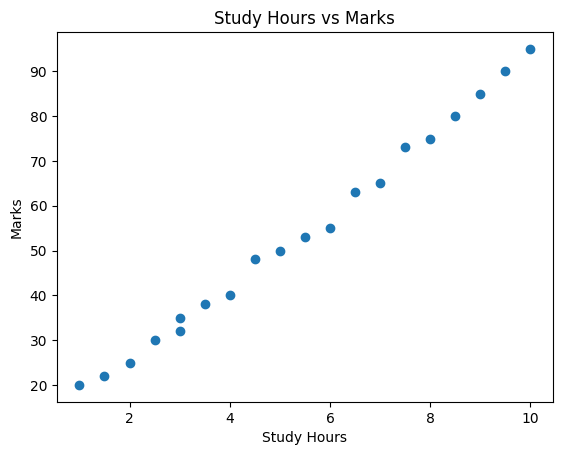

X shape: (20, 1)
y shape: (20,)
Training data: (16, 1)
Testing data: (4, 1)
Model training completed!
Slope: 8.537770578707113
Intercept: 7.616845825357089
   Actual Marks  Predicted Marks
0            20        16.154616
1            80        80.187896
2            63        63.112355
3            25        24.692387
MAE: 1.1133117361213403
MSE: 3.7323822830553923
R2 Score: 0.9941635929897492
Study Hours: 7
Predicted Marks: 67.38


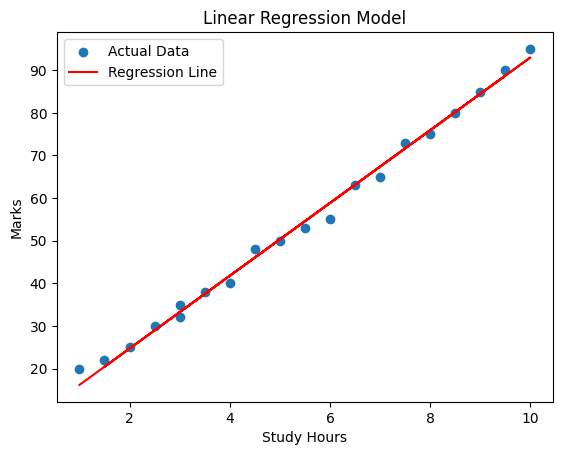

In [9]:
import pandas as pd

data = {
    "study_hours": [
        1,2,3,4,5,6,7,8,9,10,
        1.5,2.5,3.5,4.5,5.5,
        6.5,7.5,8.5,9.5,3
    ],
    "marks": [
        20,25,35,40,50,55,65,75,85,95,
        22,30,38,48,53,63,73,80,90,32
    ]
}

df = pd.DataFrame(data)

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

import matplotlib.pyplot as plt

plt.scatter(df["study_hours"], df["marks"])

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")

plt.show()

X = df[["study_hours"]]
y = df["marks"]

print("X shape:", X.shape)
print("y shape:", y.shape)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)




predictions = model.predict(X_test)

results = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": predictions
})

print(results)

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)


hours = 7

new_prediction = model.predict(
    pd.DataFrame({"study_hours":[hours]})
)

print(f"Study Hours: {hours}")
print(f"Predicted Marks: {new_prediction[0]:.2f}")



plt.scatter(X, y, label="Actual Data")

plt.plot(
    X,
    model.predict(X),
    color="red",
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Linear Regression Model")
plt.legend()

plt.show()